In [1]:
# Purpose: Initialize libraries, project paths, and load Punjab district boundaries.

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
import rasterio

from pathlib import Path

project_dir = Path(r"D:\SoilSenseAI")
processed_dir = project_dir / "data" / "processed"
parquet_dir = processed_dir / "parquet"
output_dir = project_dir / "outputs" / "eda"
output_dir.mkdir(parents=True, exist_ok=True)

punjab = gpd.read_file(processed_dir / "punjab_districts.geojson")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

print("Punjab districts:", len(punjab))
print("CRS:", punjab.crs)
print("EDA output directory:", output_dir)

Punjab districts: 36
CRS: EPSG:4326
EDA output directory: D:\SoilSenseAI\outputs\eda


In [2]:
# Purpose: Summarize the structure and storage of all six depth-wise datasets.

depths = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

dataset_summary = []

for depth in depths:
    file_path = parquet_dir / f"punjab_soil_{depth}.parquet"
    parquet_file = pq.ParquetFile(file_path)

    dataset_summary.append({
        "Depth": depth,
        "Records": parquet_file.metadata.num_rows,
        "Features": parquet_file.metadata.num_columns,
        "File Size (MB)": round(file_path.stat().st_size / (1024**2), 2)
    })

summary_df = pd.DataFrame(dataset_summary)

display(summary_df)

print("Total records:", f"{summary_df['Records'].sum():,}")
print("Total storage:", round(summary_df["File Size (MB)"].sum(), 2), "MB")
print("Total soil properties:", 13)

,Depth,Records,Features,File Size (MB)
0,0-5cm,3223093,16,46.54
1,5-15cm,3223093,16,46.15
2,15-30cm,3223093,16,45.94
3,30-60cm,3223093,16,45.83
4,60-100cm,3223093,16,45.71
5,100-200cm,3223093,16,46.25


Total records: 19,338,558
Total storage: 276.42 MB
Total soil properties: 13


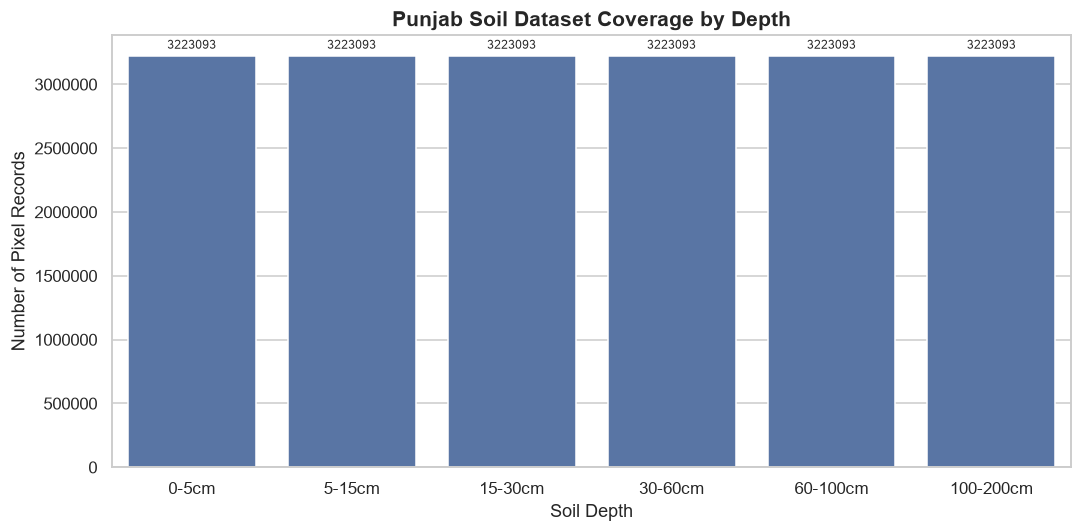

In [3]:
# Purpose: Visualize the number of records available at each soil depth.

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=summary_df,
    x="Depth",
    y="Records"
)

ax.set_title("Punjab Soil Dataset Coverage by Depth", fontsize=14, weight="bold")
ax.set_xlabel("Soil Depth")
ax.set_ylabel("Number of Pixel Records")
ax.ticklabel_format(style="plain", axis="y")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig(output_dir / "01_dataset_coverage_by_depth.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# Purpose: Calculate descriptive statistics for all soil properties at each depth.

soil_properties = [
    "bdod", "cec", "cfvo", "clay", "nitrogen", "ocd",
    "phh2o", "sand", "silt", "soc", "wv0010", "wv0033", "wv1500"
]

depth_statistics = []

for depth in depths:
    file_path = parquet_dir / f"punjab_soil_{depth}.parquet"
    df = pq.read_table(file_path, columns=soil_properties).to_pandas()

    stats = df[soil_properties].describe().T
    stats["Depth"] = depth
    depth_statistics.append(stats)

    del df

statistics_df = pd.concat(depth_statistics)
display(statistics_df.round(3))

statistics_df.to_csv(output_dir / "soil_descriptive_statistics.csv")

print("Descriptive statistics saved.")

,count,mean,std,min,25%,50%,75%,max,Depth
bdod,3222765.0,1.478,0.059,1.11,1.46,1.49,1.51,1.72,0-5cm
cec,3223093.0,16.120,2.349,7.40,14.30,16.00,17.90,26.60,0-5cm
cfvo,3223093.0,8.129,5.455,0.30,4.60,6.50,10.20,38.00,0-5cm
clay,3223093.0,22.454,2.716,10.60,20.90,22.40,23.90,40.00,0-5cm
nitrogen,3223093.0,1.134,0.484,0.28,0.86,1.05,1.29,6.54,0-5cm
...,...,...,...,...,...,...,...,...,...
silt,3223093.0,35.697,9.108,13.10,28.70,34.80,41.90,78.80,100-200cm
soc,3223093.0,3.044,1.295,1.00,2.20,2.70,3.60,42.70,100-200cm
wv0010,3223093.0,34.087,2.079,26.20,32.30,34.00,35.70,42.00,100-200cm
wv0033,3223093.0,29.555,3.339,18.40,27.80,30.80,31.90,38.60,100-200cm


Descriptive statistics saved.


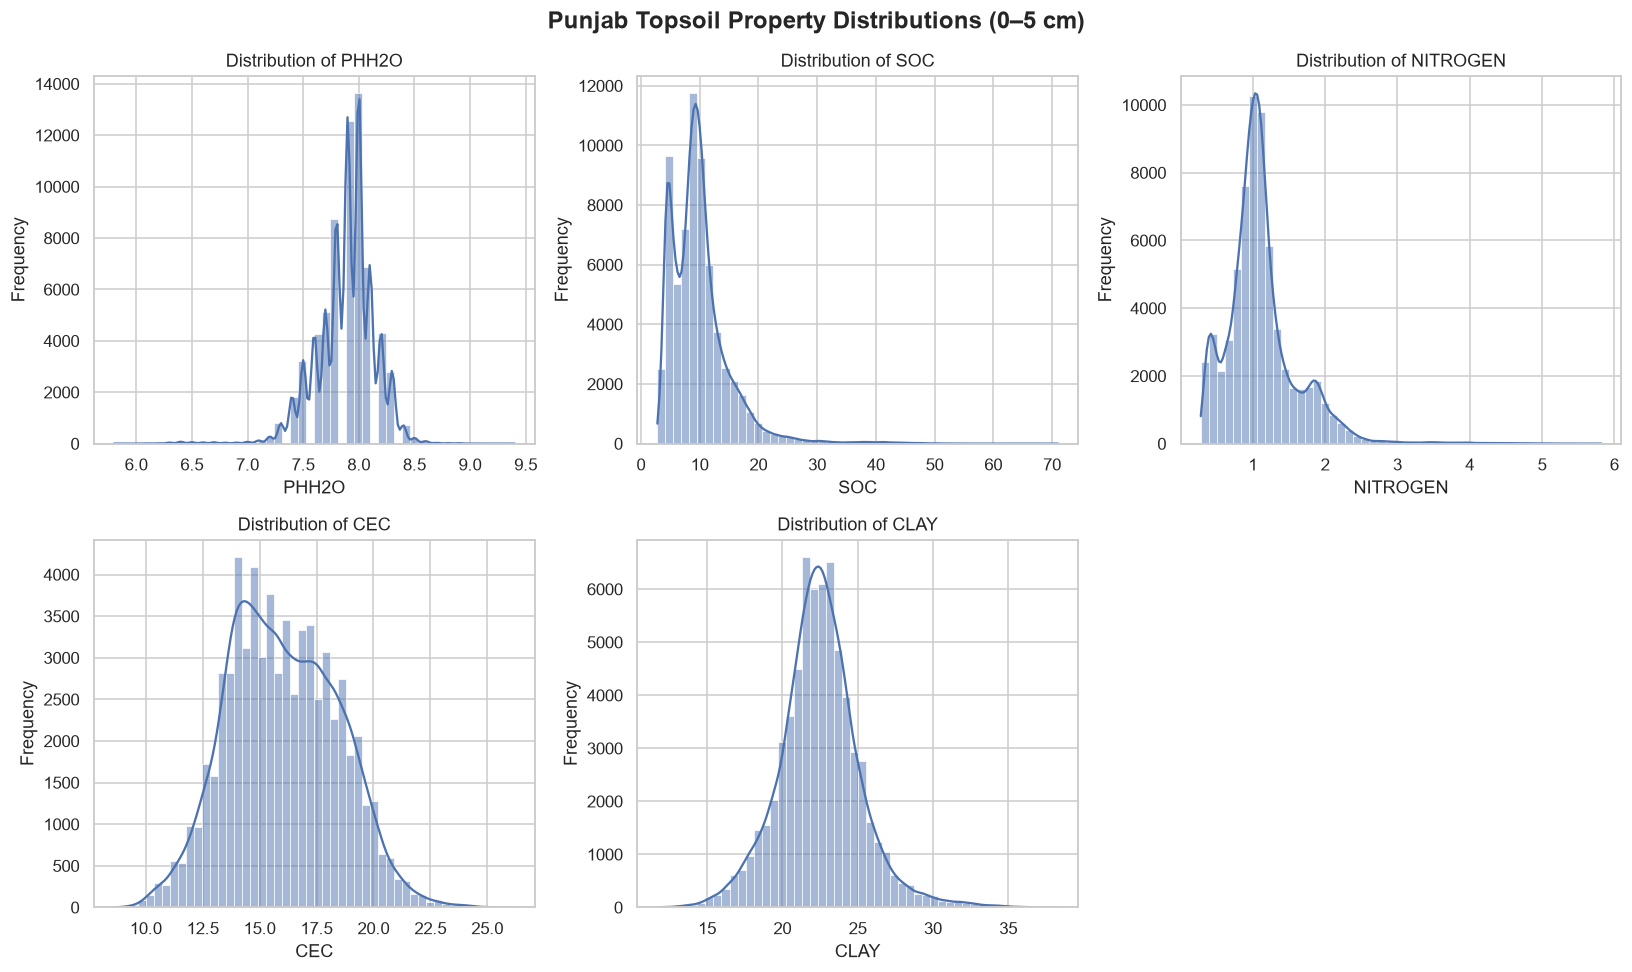

Sample records used: 66000


In [5]:
# Purpose: Visualize the distributions of important topsoil properties using a sample.

topsoil_file = pq.ParquetFile(parquet_dir / "punjab_soil_0-5cm.parquet")

plot_features = ["phh2o", "soc", "nitrogen", "cec", "clay"]
sample_batches = []

for batch in topsoil_file.iter_batches(
    batch_size=100_000,
    columns=plot_features
):
    batch_df = batch.to_pandas()
    sample_batches.append(
        batch_df.sample(n=min(2_000, len(batch_df)), random_state=42)
    )
    del batch_df

plot_df = pd.concat(sample_batches, ignore_index=True).dropna()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(plot_features):
    sns.histplot(
        data=plot_df,
        x=feature,
        bins=50,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {feature.upper()}")
    axes[i].set_xlabel(feature.upper())
    axes[i].set_ylabel("Frequency")

axes[-1].axis("off")

plt.suptitle("Punjab Topsoil Property Distributions (0–5 cm)", fontsize=16, weight="bold")
plt.tight_layout()
plt.savefig(output_dir / "02_topsoil_property_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

print("Sample records used:", len(plot_df))

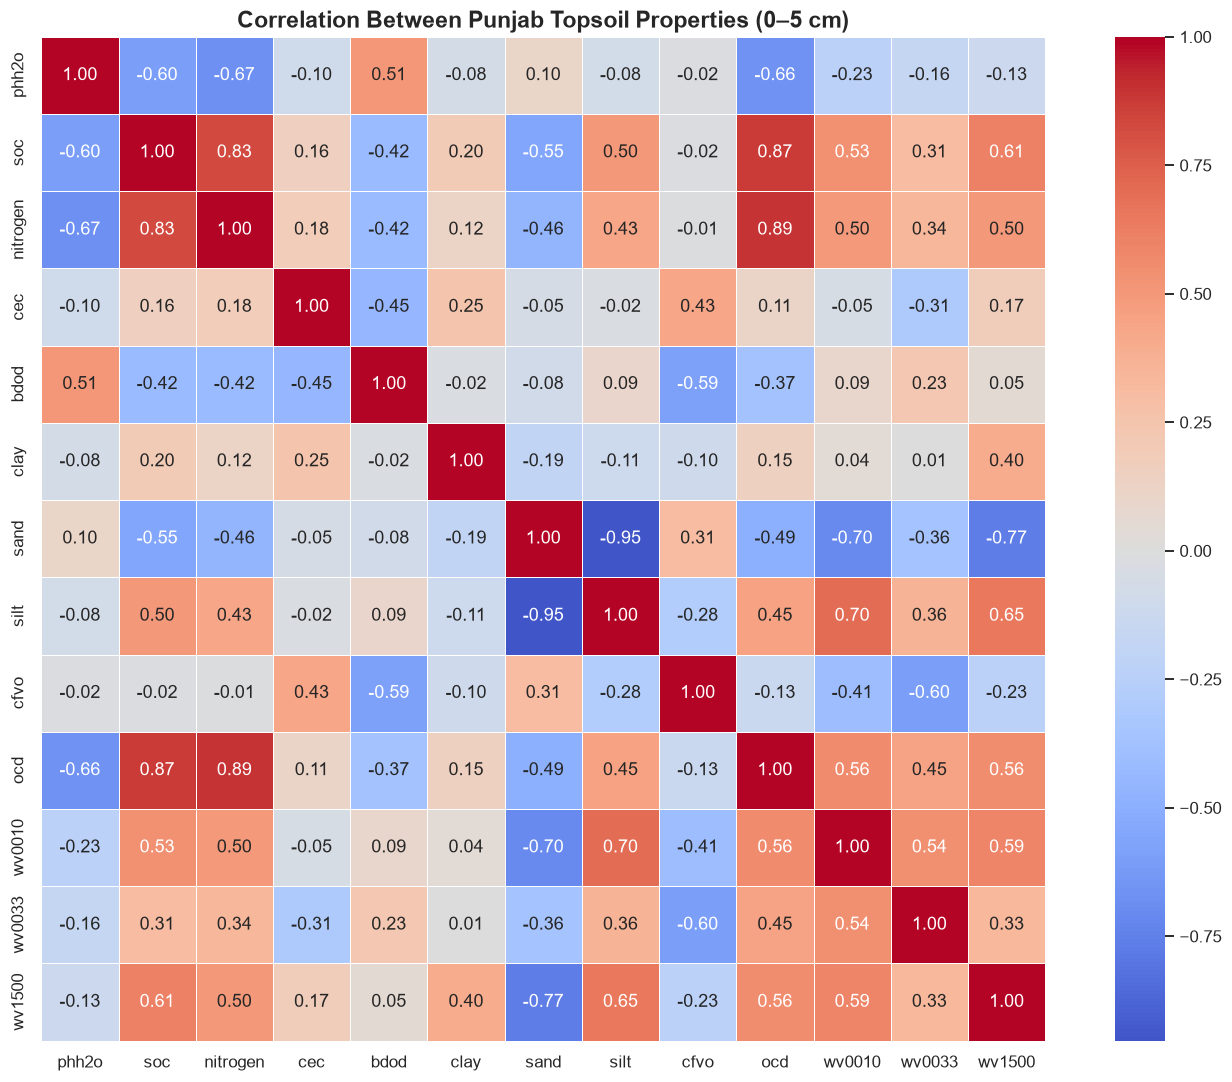

In [6]:
# Purpose: Analyze correlations among Punjab topsoil properties.

correlation_features = [
    "phh2o", "soc", "nitrogen", "cec", "bdod",
    "clay", "sand", "silt", "cfvo",
    "ocd", "wv0010", "wv0033", "wv1500"
]

correlation_data = pq.read_table(
    parquet_dir / "punjab_soil_0-5cm.parquet",
    columns=correlation_features
).to_pandas()

correlation_sample = correlation_data.sample(
    n=50_000,
    random_state=42
)

correlation_matrix = correlation_sample.corr(method="pearson")

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Between Punjab Topsoil Properties (0–5 cm)", fontsize=15, weight="bold")
plt.tight_layout()

plt.savefig(
    output_dir / "03_topsoil_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

del correlation_data, correlation_sample

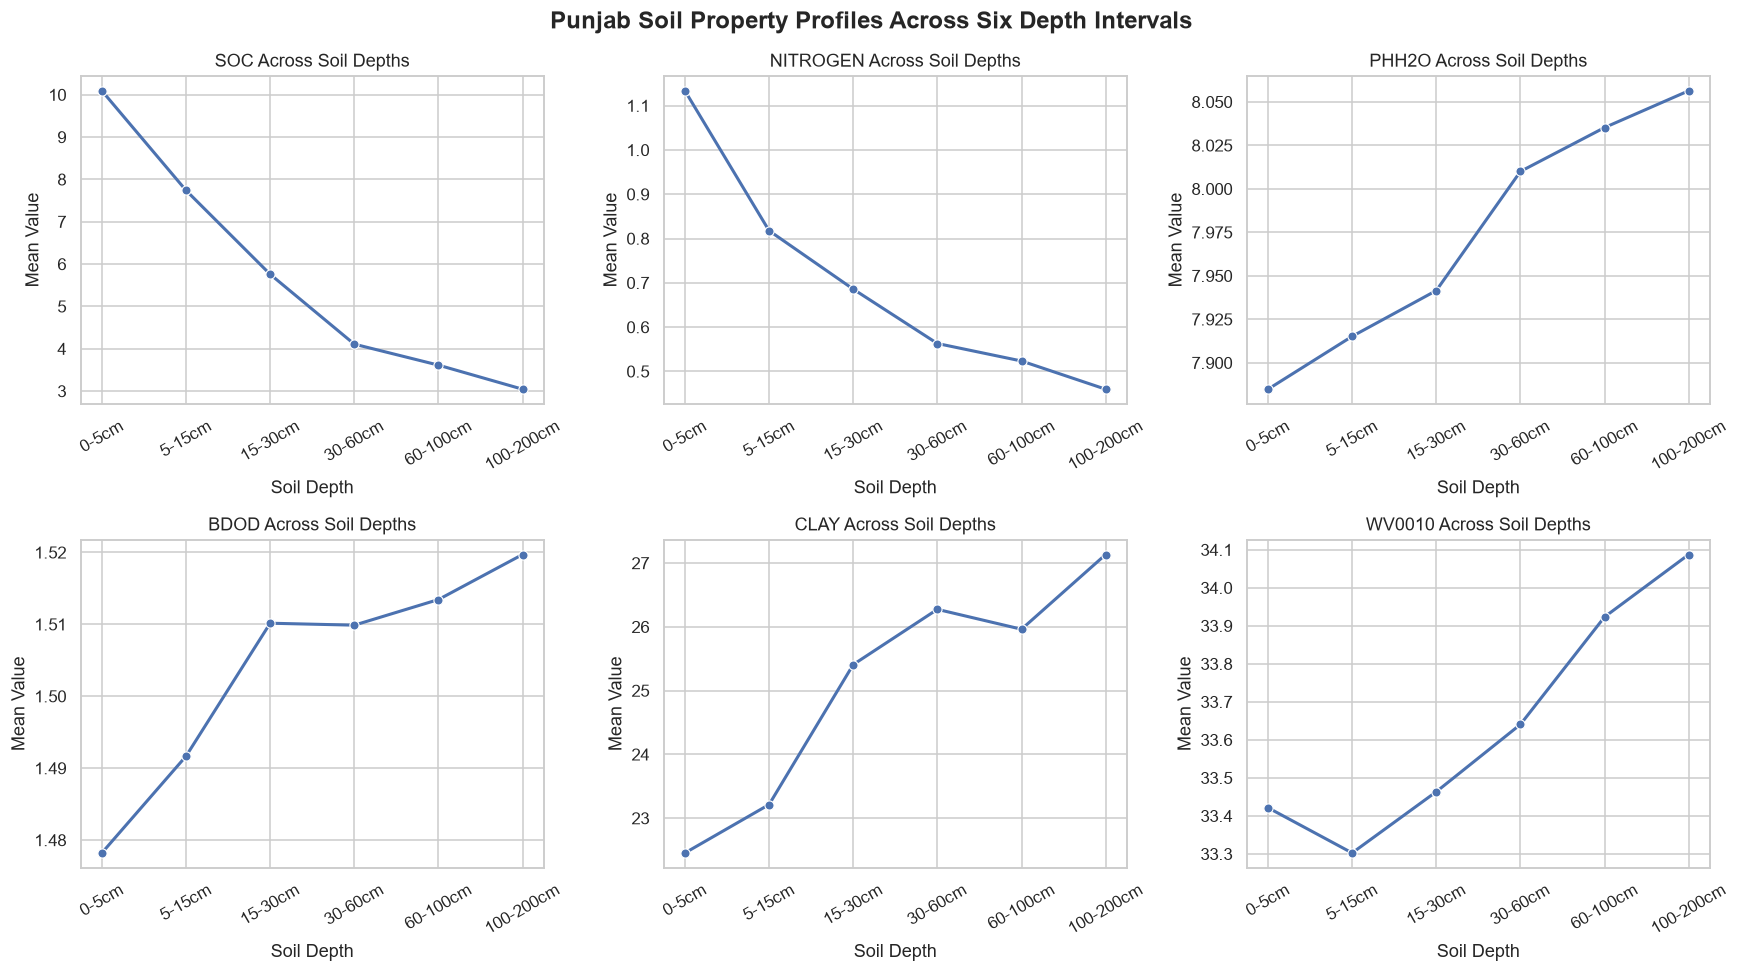

In [7]:
# Purpose: Visualize how selected soil properties change across Punjab's soil depths.

depth_order = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

profile_features = ["soc", "nitrogen", "phh2o", "bdod", "clay", "wv0010"]

profile_df = (
    statistics_df.reset_index()
    .rename(columns={"index": "Property"})
)

profile_df["Depth"] = pd.Categorical(
    profile_df["Depth"],
    categories=depth_order,
    ordered=True
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flat, profile_features):
    subset = profile_df[profile_df["Property"] == feature].sort_values("Depth")

    sns.lineplot(
        data=subset,
        x="Depth",
        y="mean",
        marker="o",
        linewidth=2,
        ax=ax
    )

    ax.set_title(f"{feature.upper()} Across Soil Depths")
    ax.set_xlabel("Soil Depth")
    ax.set_ylabel("Mean Value")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle(
    "Punjab Soil Property Profiles Across Six Depth Intervals",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.savefig(
    output_dir / "04_soil_depth_profiles.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [9]:
# Purpose: Identify the district-name column in the Punjab boundary dataset.

print(punjab.columns.tolist())

['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']


In [12]:
# Purpose: Calculate district-level topsoil averages for four key soil properties.

from rasterio.mask import mask

district_features = ["phh2o", "soc", "nitrogen", "cec"]

conversion_factors = {
    "phh2o": 10,
    "soc": 10,
    "nitrogen": 100,
    "cec": 10
}

district_results = []

punjab_native = punjab.to_crs("ESRI:54052")

for feature in district_features:

    raster_path = processed_dir / f"punjab_{feature}_0-5cm_mean_clipped.tif"

    with rasterio.open(raster_path) as src:

        for _, district in punjab_native.iterrows():

            clipped, _ = mask(
                src,
                [district.geometry.__geo_interface__],
                crop=True,
                filled=False
            )

            values = clipped[0].compressed()
            values = values[values != 0]

            district_results.append({
                "district": district["adm2_name"],
                "property": feature,
                "mean": np.mean(values) / conversion_factors[feature]
            })

district_stats = pd.DataFrame(district_results)

district_pivot = district_stats.pivot(
    index="district",
    columns="property",
    values="mean"
).reset_index()

display(district_pivot.round(3))

district_pivot.to_csv(
    output_dir / "district_level_soil_statistics.csv",
    index=False
)

print("Districts analyzed:", len(district_pivot))
print("Properties analyzed:", len(district_features))
print("Saved district statistics successfully.")

property,district,cec,nitrogen,phh2o,soc
0,Attock,18.388,1.803,7.568,18.295
1,Bahawalnagar,16.654,1.130,7.856,8.855
2,Bahawalpur,15.727,0.720,7.879,5.778
3,Bhakkar,18.122,0.934,8.131,7.256
4,Chakwal,18.125,1.509,7.538,16.865
5,Chiniot,13.730,1.058,7.987,10.400
6,Dera Ghazi Khan,17.837,1.007,8.059,7.624
7,Faisalabad,14.034,1.056,7.968,10.081
8,Gujranwala,16.505,1.236,8.152,13.284
9,Gujrat,16.186,1.704,7.547,13.522


Districts analyzed: 36
Properties analyzed: 4
Saved district statistics successfully.


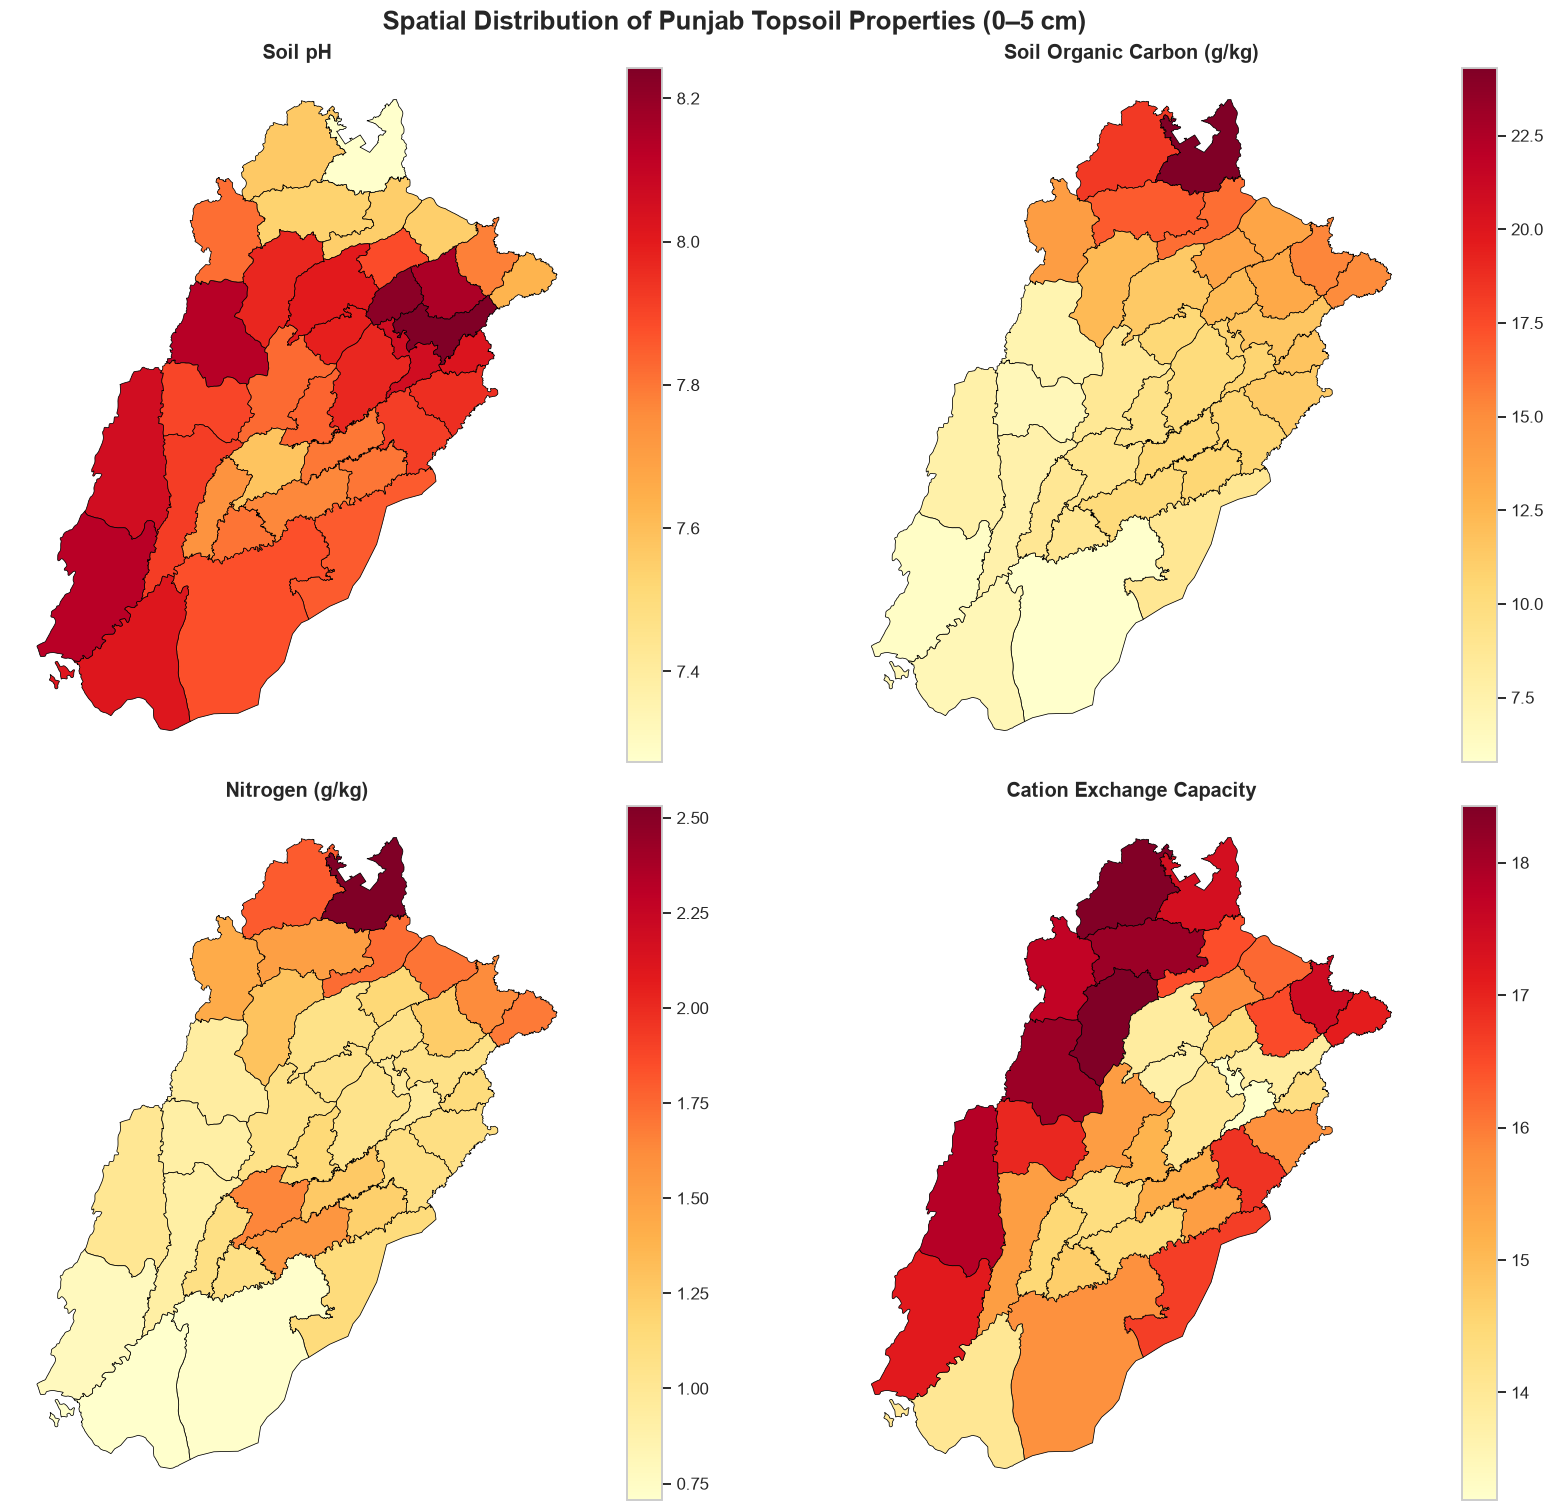

In [13]:
# Purpose: Create district-level choropleth maps of four Punjab topsoil properties.

map_data = punjab.merge(
    district_pivot,
    left_on="adm2_name",
    right_on="district",
    how="left"
)

map_features = [
    ("phh2o", "Soil pH"),
    ("soc", "Soil Organic Carbon (g/kg)"),
    ("nitrogen", "Nitrogen (g/kg)"),
    ("cec", "Cation Exchange Capacity")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for ax, (feature, title) in zip(axes.flat, map_features):

    map_data.plot(
        column=feature,
        cmap="YlOrRd",
        linewidth=0.5,
        edgecolor="black",
        legend=True,
        ax=ax,
        missing_kwds={"color": "lightgrey"}
    )

    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_axis_off()

plt.suptitle(
    "Spatial Distribution of Punjab Topsoil Properties (0–5 cm)",
    fontsize=17,
    weight="bold"
)

plt.tight_layout()

plt.savefig(
    output_dir / "05_punjab_district_soil_maps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Purpose: Compare soil depth profiles across four selected Punjab districts.

selected_districts = ["Sahiwal", "Rawalpindi", "Bahawalpur", "Faisalabad"]

profile_properties = ["soc", "nitrogen", "phh2o", "clay"]

profile_conversion = {
    "soc": 10,
    "nitrogen": 100,
    "phh2o": 10,
    "clay": 10
}

district_profile_results = []

selected_boundaries = punjab_native[
    punjab_native["adm2_name"].isin(selected_districts)
]

for depth in depth_order:
    for feature in profile_properties:

        raster_path = processed_dir / f"punjab_{feature}_{depth}_mean_clipped.tif"

        with rasterio.open(raster_path) as src:

            for _, district in selected_boundaries.iterrows():

                clipped, _ = mask(
                    src,
                    [district.geometry.__geo_interface__],
                    crop=True,
                    filled=False
                )

                values = clipped[0].compressed()
                values = values[values != 0]

                district_profile_results.append({
                    "district": district["adm2_name"],
                    "depth": depth,
                    "property": feature,
                    "mean": np.mean(values) / profile_conversion[feature]
                })

district_profile_df = pd.DataFrame(district_profile_results)

district_profile_df.to_csv(
    output_dir / "selected_district_depth_profiles.csv",
    index=False
)

print("Districts:", district_profile_df["district"].nunique())
print("Depth intervals:", district_profile_df["depth"].nunique())
print("Properties:", district_profile_df["property"].nunique())

display(district_profile_df.head(12).round(3))

Districts: 4
Depth intervals: 6
Properties: 4


,district,depth,property,mean
0,Bahawalpur,0-5cm,soc,5.778
1,Faisalabad,0-5cm,soc,10.081
2,Rawalpindi,0-5cm,soc,24.302
3,Sahiwal,0-5cm,soc,10.469
4,Bahawalpur,0-5cm,nitrogen,0.720
5,Faisalabad,0-5cm,nitrogen,1.056
6,Rawalpindi,0-5cm,nitrogen,2.531
7,Sahiwal,0-5cm,nitrogen,1.256
8,Bahawalpur,0-5cm,phh2o,7.879
9,Faisalabad,0-5cm,phh2o,7.968


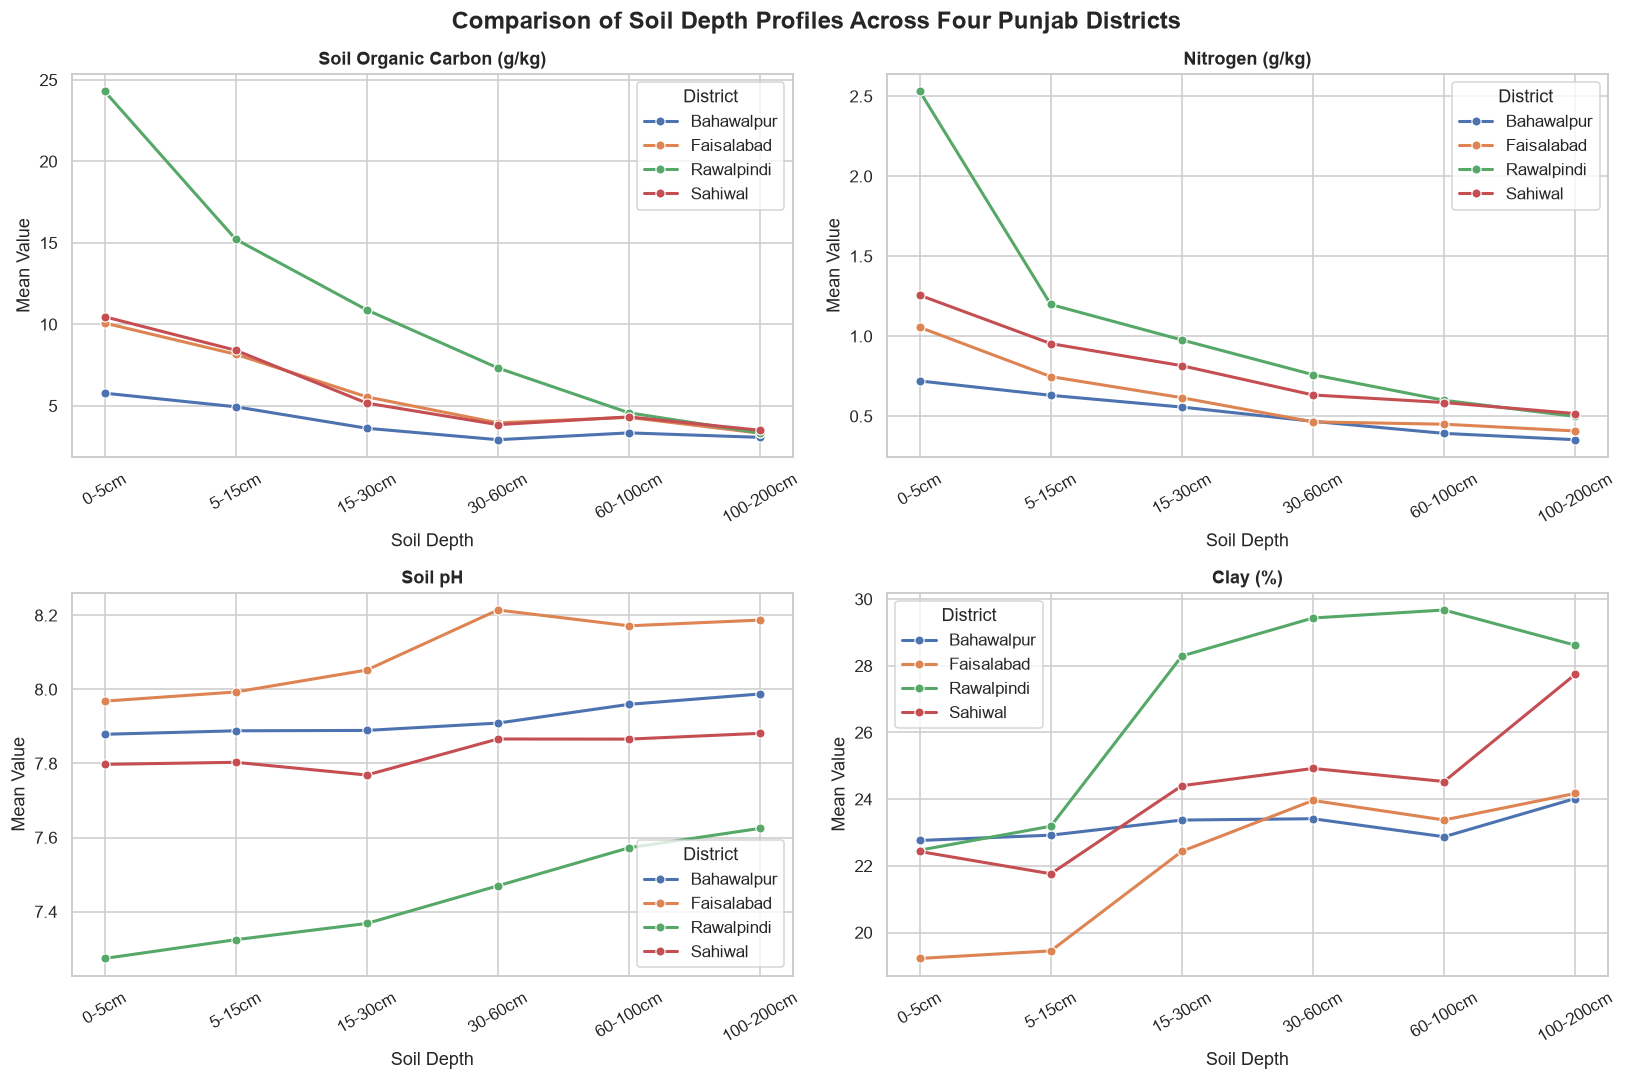

In [16]:
# Purpose: Visualize depth-wise differences in soil properties across four districts.

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

plot_properties = [
    ("soc", "Soil Organic Carbon (g/kg)"),
    ("nitrogen", "Nitrogen (g/kg)"),
    ("phh2o", "Soil pH"),
    ("clay", "Clay (%)")
]

for ax, (feature, title) in zip(axes.flat, plot_properties):

    subset = district_profile_df[
        district_profile_df["property"] == feature
    ].copy()

    sns.lineplot(
        data=subset,
        x="depth",
        y="mean",
        hue="district",
        marker="o",
        linewidth=2,
        sort=False,
        ax=ax
    )

    ax.set_title(title, weight="bold")
    ax.set_xlabel("Soil Depth")
    ax.set_ylabel("Mean Value")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="District")

plt.suptitle(
    "Comparison of Soil Depth Profiles Across Four Punjab Districts",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()

plt.savefig(
    output_dir / "06_selected_district_depth_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

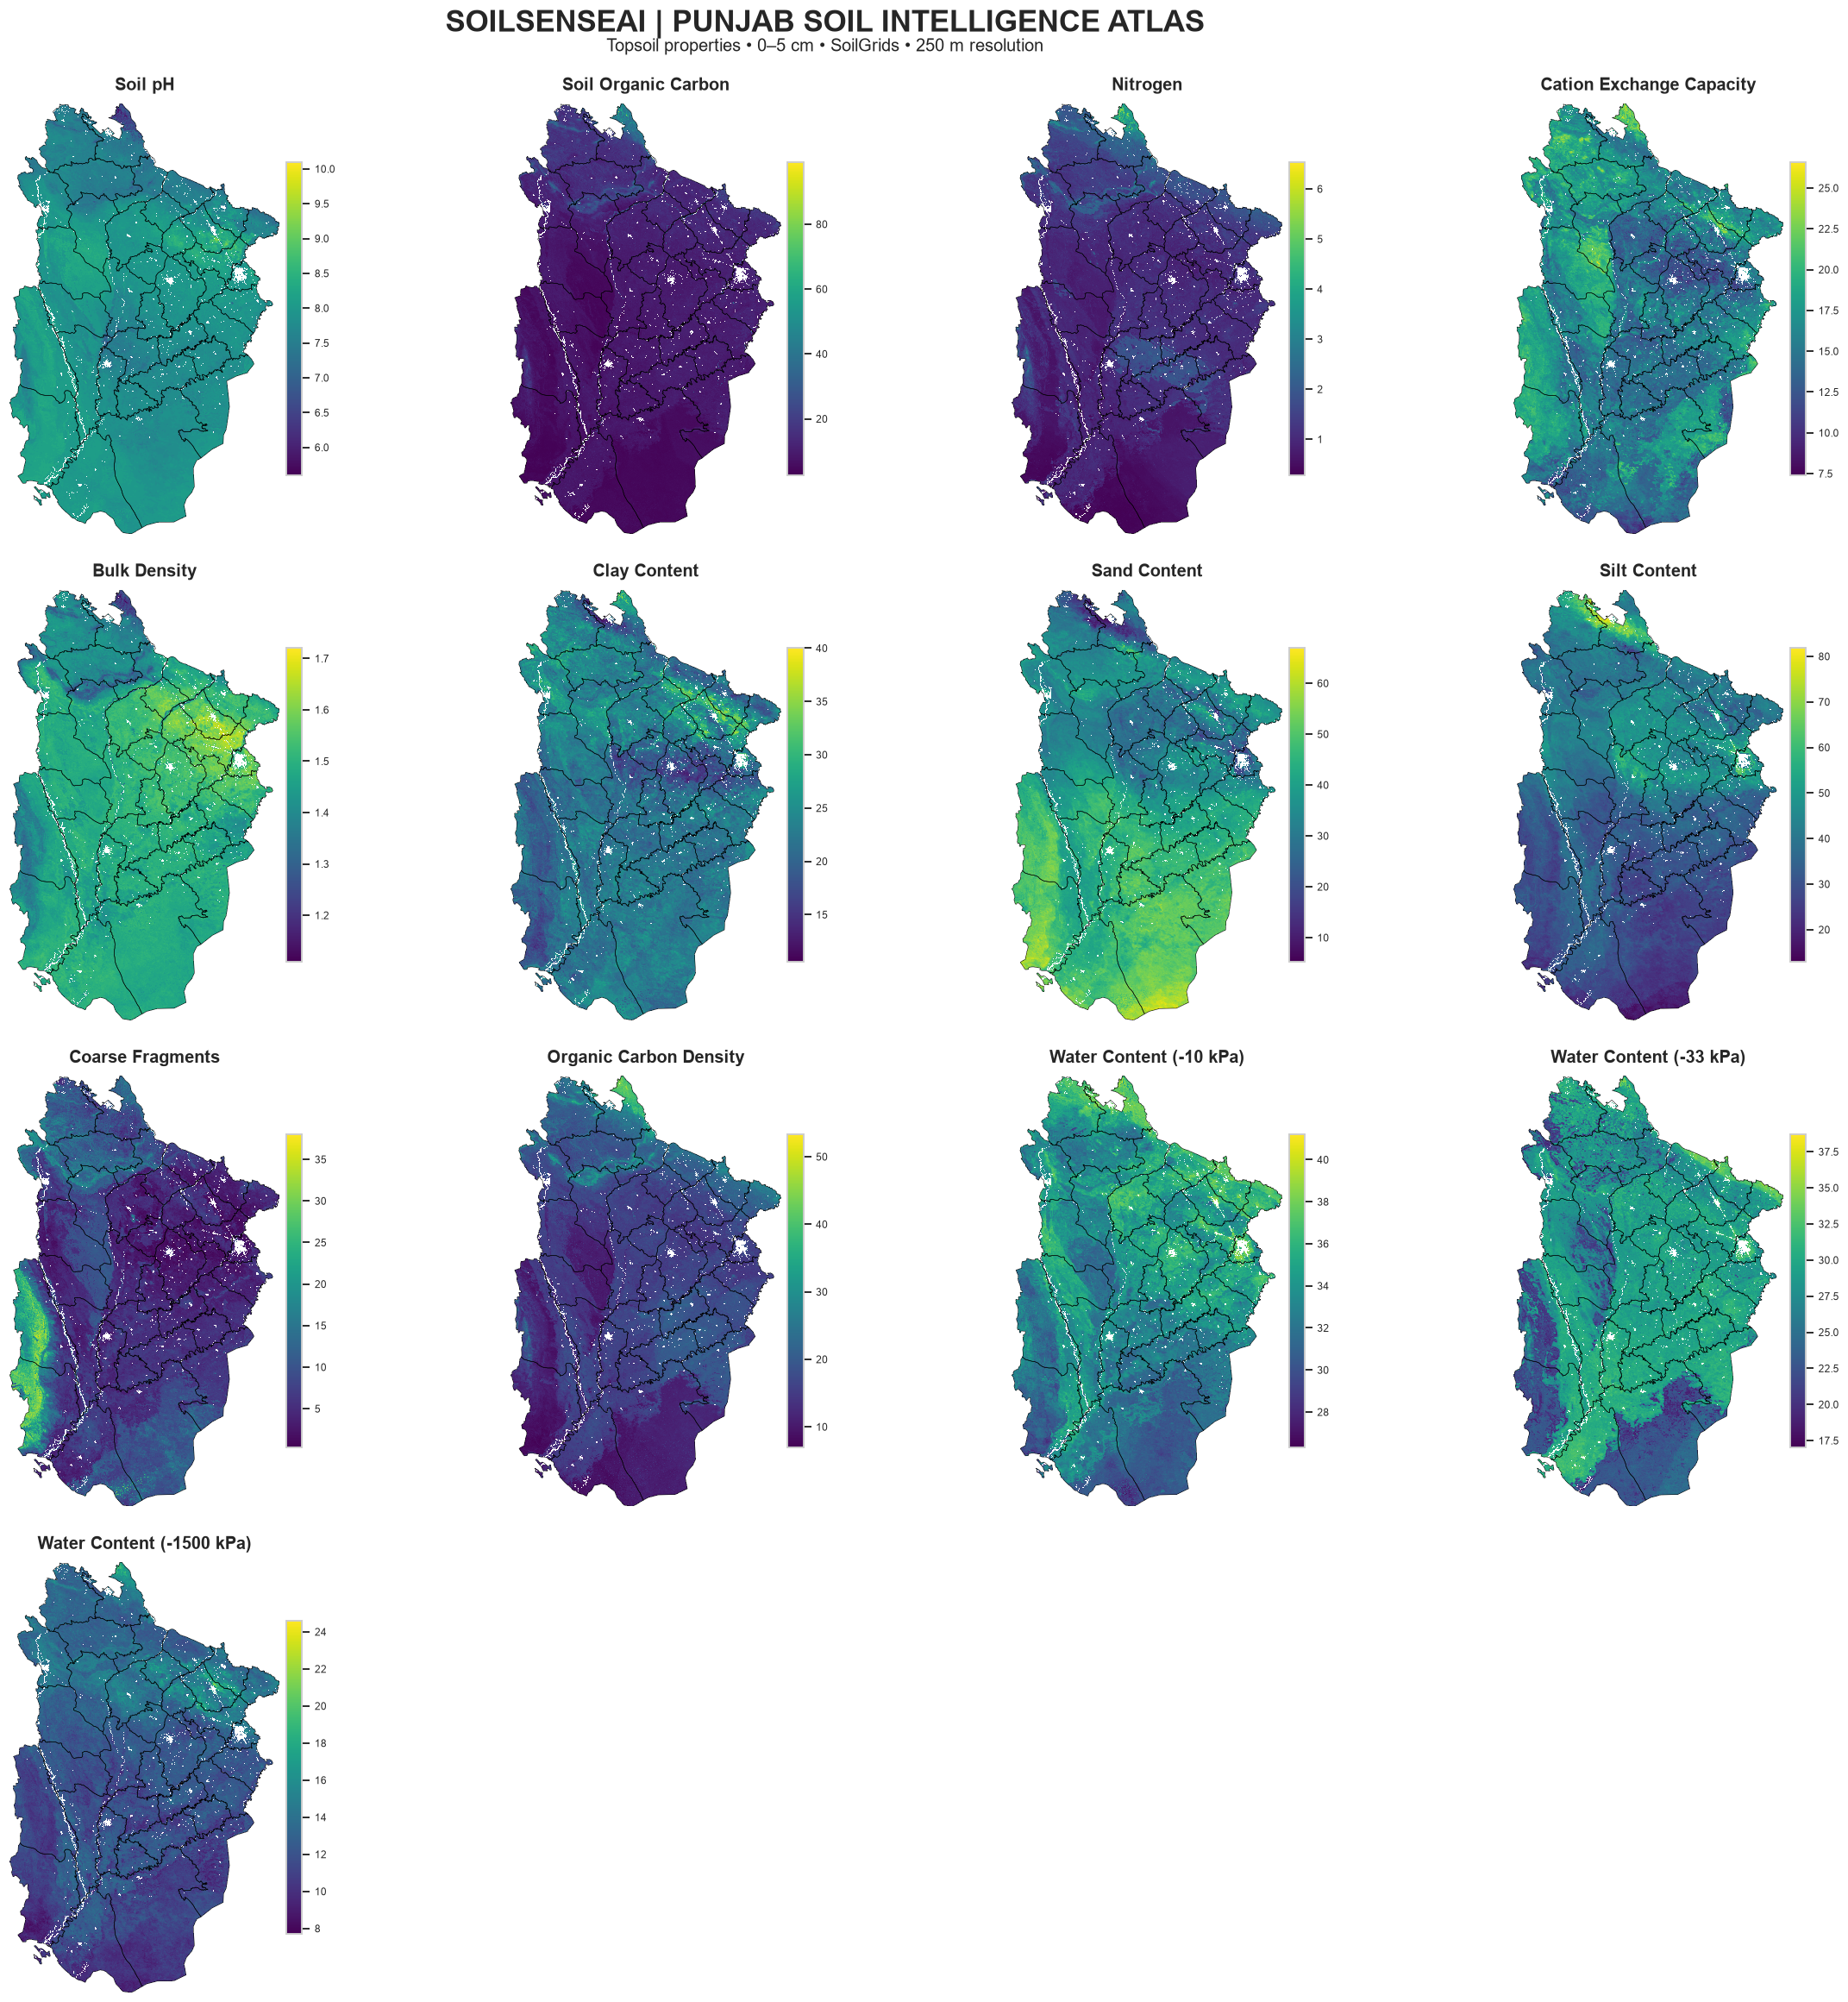

Soil properties mapped: 13
Output: D:\SoilSenseAI\outputs\eda\07_punjab_soil_intelligence_atlas.png


In [17]:
# Purpose: Create a 13-panel spatial atlas of Punjab's topsoil properties.

import rasterio
from rasterio.plot import plotting_extent

soil_features = [
    ("phh2o", "Soil pH"),
    ("soc", "Soil Organic Carbon"),
    ("nitrogen", "Nitrogen"),
    ("cec", "Cation Exchange Capacity"),
    ("bdod", "Bulk Density"),
    ("clay", "Clay Content"),
    ("sand", "Sand Content"),
    ("silt", "Silt Content"),
    ("cfvo", "Coarse Fragments"),
    ("ocd", "Organic Carbon Density"),
    ("wv0010", "Water Content (-10 kPa)"),
    ("wv0033", "Water Content (-33 kPa)"),
    ("wv1500", "Water Content (-1500 kPa)")
]

conversion = {
    "phh2o": 10,
    "soc": 10,
    "nitrogen": 100,
    "cec": 10,
    "bdod": 100,
    "clay": 10,
    "sand": 10,
    "silt": 10,
    "cfvo": 10,
    "ocd": 10,
    "wv0010": 10,
    "wv0033": 10,
    "wv1500": 10
}

fig, axes = plt.subplots(4, 4, figsize=(22, 22))
axes = axes.flatten()

boundary = punjab.to_crs("ESRI:54052")

for i, (feature, title) in enumerate(soil_features):

    ax = axes[i]

    raster_path = (
        processed_dir /
        f"punjab_{feature}_0-5cm_mean_clipped.tif"
    )

    with rasterio.open(raster_path) as src:

        data = src.read(1).astype("float32")
        data = np.ma.masked_equal(data, 0)
        data = data / conversion[feature]

        extent = plotting_extent(src)

        image = ax.imshow(
            data,
            extent=extent,
            cmap="viridis",
            interpolation="nearest"
        )

        boundary.boundary.plot(
            ax=ax,
            color="black",
            linewidth=0.35
        )

        ax.set_title(
            title,
            fontsize=13,
            fontweight="bold",
            pad=10
        )

        ax.set_axis_off()

        colorbar = fig.colorbar(
            image,
            ax=ax,
            fraction=0.035,
            pad=0.015
        )

        colorbar.ax.tick_params(labelsize=8)

    del data

# Hide the three unused panels.
for ax in axes[len(soil_features):]:
    ax.set_visible(False)

fig.suptitle(
    "SOILSENSEAI | PUNJAB SOIL INTELLIGENCE ATLAS",
    fontsize=23,
    fontweight="bold",
    y=0.985
)

fig.text(
    0.5,
    0.965,
    "Topsoil properties • 0–5 cm • SoilGrids • 250 m resolution",
    ha="center",
    fontsize=13
)

plt.subplots_adjust(
    top=0.94,
    bottom=0.035,
    left=0.035,
    right=0.97,
    hspace=0.13,
    wspace=0.12
)

plt.savefig(
    output_dir / "07_punjab_soil_intelligence_atlas.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Soil properties mapped:", len(soil_features))
print("Output:", output_dir / "07_punjab_soil_intelligence_atlas.png")


# SoilSenseAI — Punjab Soil Exploratory Data Analysis

**Project:** SoilSenseAI — Punjab Soil Intelligence and Agricultural Decision Support System  
**Notebook:** 07 — Punjab Soil Exploratory Analysis  
**Study Area:** Punjab, Pakistan  
**Pilot District:** Sahiwal  
**Data Source:** ISRIC SoilGrids  
**Spatial Resolution:** Approximately 250 metres  
**Analysis:** Topsoil and multi-depth exploratory analysis

---

## 1. Project Overview

SoilSenseAI aims to develop a province-wide soil intelligence and agricultural decision-support system for Punjab, Pakistan.

The project explores soil properties, their geographical distribution, depth-wise variations, and relationships with other soil characteristics. Its long-term objective is to support soil health assessment, soil classification, crop suitability analysis, and evidence-based agricultural recommendations.

Although the initial analysis covers all 36 districts of Punjab, Sahiwal is selected as the pilot district for future field-level validation.

## 2. Objectives of This Notebook

The purpose of this notebook is to explore and understand the acquired Punjab SoilGrids dataset before developing machine learning models.

The main objectives are:

1. Examine the size, structure, and coverage of the acquired dataset.
2. Calculate descriptive statistics for soil properties across different depths.
3. Understand the distributions of major topsoil properties.
4. Investigate relationships between soil properties using correlation analysis.
5. Examine how soil characteristics change with depth.
6. Calculate district-level soil statistics for Punjab.
7. Visualize geographical variations using district-level choropleth maps.
8. Compare soil profiles across selected districts.
9. Generate a spatial atlas of all 13 topsoil properties.

## 3. Dataset Sources

### 3.1 Soil Property Data

Soil property data were acquired from **ISRIC SoilGrids** using its Web Coverage Service (WCS).

The dataset contains gridded estimates of soil properties at approximately 250 m spatial resolution.

The following 13 numerical properties are included in the multi-depth Parquet dataset:

| Property | Description |
|---|---|
| phh2o | Soil pH |
| soc | Soil Organic Carbon |
| nitrogen | Total Nitrogen |
| cec | Cation Exchange Capacity |
| bdod | Bulk Density |
| clay | Clay Content |
| sand | Sand Content |
| silt | Silt Content |
| cfvo | Coarse Fragments Volume |
| ocd | Organic Carbon Density |
| wv0010 | Water Content at -10 kPa |
| wv0033 | Water Content at -33 kPa |
| wv1500 | Water Content at -1500 kPa |

### 3.2 Geographical Boundaries

Punjab district boundaries were obtained from the Pakistan administrative boundary dataset (OCHA/HDX COD-AB).

The dataset contains 36 districts of Punjab and was used for geographical analysis and district-level statistics.

## 4. Dataset Structure and Coverage

The acquired dataset contains six soil depth intervals:

- 0–5 cm
- 5–15 cm
- 15–30 cm
- 30–60 cm
- 60–100 cm
- 100–200 cm

Each depth contains approximately 3,223,093 spatial records.

| Description | Value |
|---|---:|
| Number of districts | 36 |
| Number of depth intervals | 6 |
| Soil properties | 13 |
| Records per depth | 3,223,093 |
| Total pixel-depth records | 19,338,558 |
| Raster resolution | Approximately 250 m |
| Compressed Parquet size | Approximately 276.42 MB |

**Important:** The 19.3 million records represent spatial pixels across six depth intervals. They are not 19.3 million independent laboratory soil samples.

## 5. Exploratory Data Analysis

### 5.1 Dataset Inventory

The first analysis examined the six Parquet files, their dimensions, file sizes, and property coverage.

A dataset coverage visualization was generated to compare the available spatial records across depth intervals.

**Output:** `01_dataset_coverage_by_depth.png`

### 5.2 Descriptive Statistics

Descriptive statistics were calculated for all 13 soil properties across the six depth intervals.

The analysis included:

- Mean
- Standard deviation
- Minimum
- 25th percentile
- Median
- 75th percentile
- Maximum
- Non-missing observation count

The resulting statistics were exported for further analysis.

**Output:** `soil_descriptive_statistics.csv`

### 5.3 Topsoil Property Distributions

The distributions of five important topsoil properties were examined:

- Soil pH
- Soil Organic Carbon
- Nitrogen
- Cation Exchange Capacity
- Clay Content

Key observations:

- Soil pH values are concentrated primarily between approximately 7 and 8.5, indicating generally neutral-to-alkaline estimated topsoil conditions.
- Soil Organic Carbon has a right-skewed distribution, with most observations concentrated at lower values and a smaller number of higher values.
- Nitrogen also shows a right-skewed distribution with a secondary concentration around higher values.
- CEC is approximately bell-shaped, with most observations concentrated around 15–17.5 cmol(c)/kg.
- Clay content is concentrated around 22–23%.

**Output:** `02_topsoil_property_distributions.png`

### 5.4 Correlation Analysis

Pearson correlation analysis was performed using a sample of 50,000 topsoil records.

Important observed relationships:

- SOC and Nitrogen: approximately +0.83.
- Sand and Silt: approximately -0.95.
- Soil pH and Nitrogen: approximately -0.67.
- Soil pH and SOC: approximately -0.60.
- Soil pH and Bulk Density: approximately +0.51.

These relationships indicate that some soil properties vary together and may contain overlapping information.

Soil texture fractions (clay, sand, and silt) are compositional variables, meaning their percentages collectively represent the soil texture composition.

**Output:** `03_topsoil_correlation_heatmap.png`

### 5.5 Soil Depth Profiles

Six depth intervals were compared to understand vertical variations in soil characteristics.

Major observations:

- Soil Organic Carbon decreases substantially with increasing depth.
- Nitrogen also decreases with depth.
- Soil pH shows a slight increase in deeper layers.
- Bulk density generally increases with depth.
- Clay content changes across the soil profile, with higher values appearing in some deeper intervals.
- Water retention characteristics vary across the different depth intervals.

These observations demonstrate why analysing only surface soil may provide an incomplete picture of soil conditions.

**Output:** `04_soil_depth_profiles.png`

### 5.6 District-Level Soil Statistics

District-level mean values were calculated for four topsoil properties:

- Soil pH
- Soil Organic Carbon
- Nitrogen
- Cation Exchange Capacity

The analysis covered all 36 districts of Punjab.

Selected findings:

| Property | Highest district mean | Lowest district mean |
|---|---|---|
| SOC | Rawalpindi | Bahawalpur |
| Nitrogen | Rawalpindi | Rahim Yar Khan |
| pH | Sheikhupura | Rawalpindi |
| CEC | Khushab | Nankana Sahib |

Estimated topsoil values for the pilot district, Sahiwal:

| Property | District Mean |
|---|---:|
| pH | 7.798 |
| SOC | 10.469 g/kg |
| Nitrogen | 1.256 g/kg |
| CEC | 15.249 cmol(c)/kg |

The district statistics were exported for further geographical and comparative analysis.

**Output:** `district_level_soil_statistics.csv`

### 5.7 Punjab District Soil Maps

Four choropleth maps were generated to visualize district-level variations in:

- Soil pH
- Soil Organic Carbon
- Nitrogen
- Cation Exchange Capacity

The maps reveal geographical differences between northern, central, western, and southern Punjab.

The spatial patterns of SOC and nitrogen are broadly similar, consistent with their observed positive correlation.

**Output:** `05_punjab_district_soil_maps.png`

### 5.8 Selected District Depth Comparison

Four districts were selected for a more detailed comparison:

- Sahiwal
- Rawalpindi
- Bahawalpur
- Faisalabad

The analysis compared SOC, Nitrogen, pH, and Clay Content across all six depth intervals.

Key observations:

- Rawalpindi has considerably higher estimated surface SOC and nitrogen than the other selected districts.
- SOC and nitrogen decrease with depth across all four districts.
- Soil pH profiles differ between districts.
- Clay content follows different depth-wise patterns, demonstrating geographical variation in soil profiles.

**Output:** `selected_district_depth_profiles.csv`

**Visualization:** `06_selected_district_depth_comparison.png`

### 5.9 Punjab Soil Intelligence Atlas

A combined spatial atlas was generated to visualize all 13 available topsoil properties across Punjab.

Each property is displayed in an individual map panel with its own colour scale.

The atlas includes:

- Soil pH
- Soil Organic Carbon
- Nitrogen
- Cation Exchange Capacity
- Bulk Density
- Clay
- Sand
- Silt
- Coarse Fragments Volume
- Organic Carbon Density
- Water Content at -10 kPa
- Water Content at -33 kPa
- Water Content at -1500 kPa

This visualization provides a province-wide view of the geographical distribution of the available soil properties.

**Output:** `07_punjab_soil_intelligence_atlas.png`

## 6. Generated Outputs

All notebook outputs are stored in `outputs/eda/`.

| Output | Description |
|---|---|
| 01_dataset_coverage_by_depth.png | Dataset coverage across depths |
| 02_topsoil_property_distributions.png | Topsoil property distributions |
| 03_topsoil_correlation_heatmap.png | Correlation between soil properties |
| 04_soil_depth_profiles.png | Province-wide depth profiles |
| 05_punjab_district_soil_maps.png | Four district-level choropleth maps |
| 06_selected_district_depth_comparison.png | Selected district depth comparison |
| 07_punjab_soil_intelligence_atlas.png | Spatial atlas of 13 soil properties |
| soil_descriptive_statistics.csv | Descriptive statistics |
| district_level_soil_statistics.csv | District-level mean values |
| selected_district_depth_profiles.csv | Selected district depth statistics |

## 7. Important Limitations

1. **Gridded estimates:** SoilGrids provides modelled spatial estimates rather than direct laboratory measurements at every pixel.
2. **Independent validation:** The current analysis has not yet been validated against independent Punjab laboratory or field observations.
3. **Missing agricultural indicators:** The current Parquet dataset does not contain Electrical Conductivity (EC), available Phosphorus (P), or Potassium (K).
4. **Spatial aggregation:** District averages can hide substantial variation within individual districts.
5. **Correlation limitations:** Correlation does not establish causation, and relationships between SoilGrids-derived properties are not independent experimental evidence.
6. **Resolution limitations:** A 250 m grid cannot represent every field-level soil variation.
7. **Data coverage:** Organic Carbon Stock (OCS) was acquired separately as a 0–30 cm raster and is not included in the current multi-depth Parquet dataset.

## 8. Research Implications

The EDA establishes a geographical and statistical understanding of Punjab's estimated soil characteristics.

The results suggest that:

- Soil properties vary geographically across Punjab.
- Soil characteristics change with depth.
- Some soil properties have strong statistical relationships.
- District-level comparisons can help identify areas for more detailed investigation.
- Spatial maps can support the development of soil intelligence and agricultural decision-support tools.

However, these findings should be treated as exploratory evidence rather than verified field-level soil conditions.

## 9. Future Work

The next phase will focus on improving the dataset and preparing it for agricultural intelligence applications.

Planned activities:

1. Acquire Punjab soil laboratory observations, particularly EC, available phosphorus, potassium, pH, and organic matter.
2. Obtain anonymized sample coordinates, sampling dates, and sampling depths wherever available.
3. Compare SoilGrids estimates with independent field and laboratory observations.
4. Investigate soil classification and soil health assessment methods.
5. Develop explainable machine learning models where suitable training and validation data are available.
6. Explore crop suitability and agricultural decision-support applications.
7. Conduct pilot field validation in Sahiwal before extending the validation process across Punjab.

## 10. Conclusion

This notebook completes the initial exploratory analysis of the acquired Punjab SoilGrids dataset.

The analysis covers six soil depth intervals, 13 numerical soil properties, and all 36 districts of Punjab. It includes statistical summaries, distributions, correlation analysis, depth profiles, district comparisons, geographical maps, and a combined spatial atlas.

The work provides a foundation for the next research phase of SoilSenseAI: integrating independent soil observations, improving soil-property coverage, validating spatial estimates, and developing practical agricultural intelligence applications.

**No supervised prediction model or validated crop recommendation system is claimed in this notebook.**
